# Vishal Athawale

# Car Price Prediction with Machine Learning — Task 3

## Objective
Build regression models to predict the **selling price of a used car** using vehicle attributes such as brand, age, mileage, fuel type, transmission, engine, power, and ownership information.

This notebook uses the supplied **`cardekho.csv`** dataset and follows the requested workflow:
**Data loading → inspection → cleaning → feature engineering → EDA → encoding → correlation analysis → train/test split → two regression models → evaluation → feature importance → findings → conclusion.**


## Project Checklist

- Clean and inspect the supplied dataset.
- Handle null values, duplicates, and inconsistent categorical values.
- Engineer **car age** from `year`.
- Extract **brand** from `name`.
- Perform the required EDA:
  - selling-price distribution
  - selling price vs fuel type
  - selling price vs car age
- Encode categorical variables.
- Create a feature correlation heatmap.
- Split data into training and testing sets.
- Train at least two regression models.
- Evaluate using **MAE, RMSE, and R²**.
- Create a feature-importance chart for the best-performing model.
- Keep results dynamic and reproducible.


## 1. Libraries and Configuration

In [4]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
TEST_SIZE = 0.20
REFERENCE_YEAR = 2026

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)


## 2. Load the Supplied Dataset

The notebook expects `cardekho.csv` to be in the same folder as the notebook.

In [6]:
DATA_PATH = "cardekho.csv"
df = pd.read_csv(DATA_PATH)

print(f"Dataset shape: {df.shape}")
display(df.head())


Dataset shape: (8128, 12)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78,5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.2,5.0


## 3. Initial Data Inspection

In [4]:
print("Data types:")
display(df.dtypes.to_frame("dtype"))

print("\nMissing values:")
display(df.isnull().sum().to_frame("missing_values"))

print(f"\nDuplicate rows: {df.duplicated().sum()}")

print("\nDescriptive statistics:")
display(df.describe(include="all").T)


Data types:


,dtype
name,str
year,int64
selling_price,int64
km_driven,int64
fuel,str
seller_type,str
transmission,str
owner,str
mileage(km/ltr/kg),float64
engine,float64



Missing values:


,missing_values
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0
mileage(km/ltr/kg),221
engine,221



Duplicate rows: 1202

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
name,8128,2058,Maruti Swift Dzire VDI,129,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,8128.0,NaN,NaN,NaN,2013.804011,4.044249,1983.0,2011.0,2015.0,2017.0,2020.0
selling_price,8128.0,NaN,NaN,NaN,638271.807702,806253.403508,29999.0,254999.0,450000.0,675000.0,10000000.0
km_driven,8128.0,NaN,NaN,NaN,69819.510827,56550.554958,1.0,35000.0,60000.0,98000.0,2360457.0
fuel,8128,4,Diesel,4402,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_type,8128,3,Individual,6766,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transmission,8128,2,Manual,7078,NaN,NaN,NaN,NaN,NaN,NaN,NaN
owner,8128,5,First Owner,5289,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mileage(km/ltr/kg),7907.0,NaN,NaN,NaN,19.418783,4.037145,0.0,16.78,19.3,22.32,42.0
engine,7907.0,NaN,NaN,NaN,1458.625016,503.916303,624.0,1197.0,1248.0,1582.0,3604.0


### Initial observations

The supplied dataset contains **8,128 rows and 12 columns**. Missing values are present in `mileage(km/ltr/kg)`, `engine`, `max_power`, and `seats`. Duplicate rows are also present, so both issues will be handled during cleaning.

`max_power` is stored as an object column and will be converted to numeric where possible.


## 4. Data Cleaning

In [5]:
# Work on a copy so the original loaded data remains unchanged.
clean_df = df.copy()

# Remove exact duplicate records.
duplicates_before = clean_df.duplicated().sum()
clean_df = clean_df.drop_duplicates().reset_index(drop=True)

# Standardize text columns: trim whitespace and normalize case.
categorical_columns = ["name", "fuel", "seller_type", "transmission", "owner"]
for column in categorical_columns:
    clean_df[column] = clean_df[column].astype("string").str.strip()

for column in ["fuel", "seller_type", "transmission", "owner"]:
    clean_df[column] = clean_df[column].str.lower()

# Convert max_power to numeric. Non-numeric entries become NaN and are imputed later.
clean_df["max_power"] = pd.to_numeric(clean_df["max_power"], errors="coerce")

# Remove clearly invalid target values if any exist.
invalid_price_rows = (clean_df["selling_price"] <= 0).sum()
if invalid_price_rows:
    clean_df = clean_df[clean_df["selling_price"] > 0].copy()

print(f"Duplicate rows removed: {duplicates_before}")
print(f"Invalid selling-price rows removed: {invalid_price_rows}")
print(f"Shape after cleaning: {clean_df.shape}")

print("\nMissing values after cleaning (before modeling imputation):")
display(clean_df.isnull().sum().to_frame("missing_values"))


Duplicate rows removed: 1202
Invalid selling-price rows removed: 0
Shape after cleaning: (6926, 12)

Missing values after cleaning (before modeling imputation):


,missing_values
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0
mileage(km/ltr/kg),208
engine,208


## 5. Feature Engineering

Two checklist-required features are created:

- **Car age** = reference year − manufacturing year.
- **Brand** = first word in the car `name`.

The reference year is set to **2026** so the age calculation is reproducible.

In [6]:
clean_df["car_age"] = REFERENCE_YEAR - clean_df["year"]

# Extract the first token from the vehicle name as the brand.
clean_df["brand"] = clean_df["name"].str.split().str[0].str.lower()

# Guard against impossible ages.
clean_df.loc[clean_df["car_age"] < 0, "car_age"] = np.nan

print("Sample engineered features:")
display(clean_df[["name", "year", "brand", "car_age"]].head())

print("\nUnique brands:", clean_df["brand"].nunique())
print("Car-age summary:")
display(clean_df["car_age"].describe())


Sample engineered features:


,name,year,brand,car_age
0,Maruti Swift Dzire VDI,2014,maruti,12.0
1,Skoda Rapid 1.5 TDI Ambition,2014,skoda,12.0
2,Honda City 2017-2020 EXi,2006,honda,20.0
3,Hyundai i20 Sportz Diesel,2010,hyundai,16.0
4,Maruti Swift VXI BSIII,2007,maruti,19.0



Unique brands: 32
Car-age summary:


count    6926.000000
mean       12.579700
std         4.078286
min         6.000000
25%         9.000000
50%        12.000000
75%        15.000000
max        43.000000
Name: car_age, dtype: float64

## 6. Exploratory Data Analysis

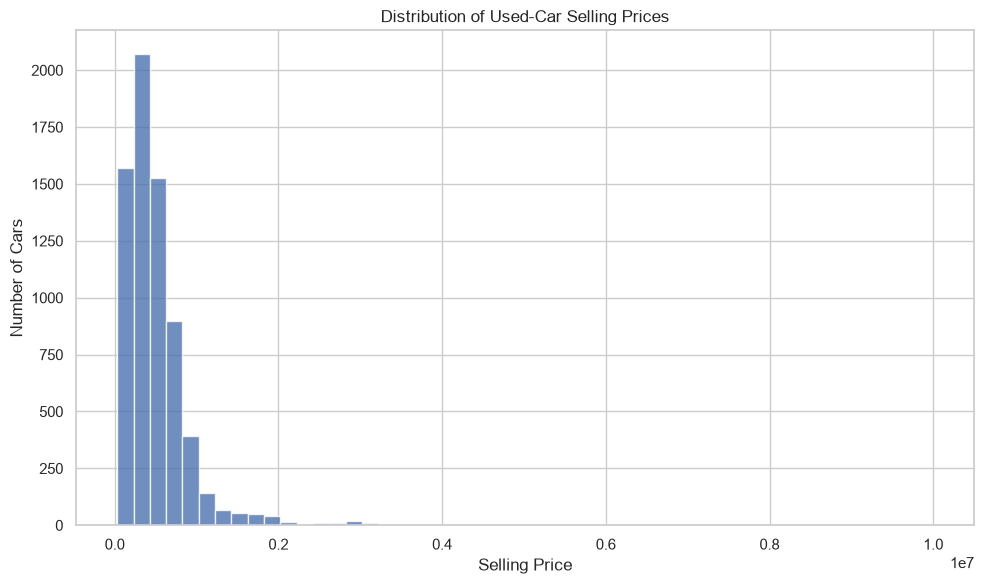

Selling-price summary:


,selling_price
count,6.926000e+03
mean,5.172707e+05
std,5.197670e+05
min,2.999900e+04
25%,2.500000e+05
50%,4.000000e+05
75%,6.335000e+05
max,1.000000e+07


In [7]:
plt.figure(figsize=(10, 6))
plt.hist(clean_df["selling_price"], bins=50, alpha=0.8)
plt.title("Distribution of Used-Car Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Number of Cars")
plt.tight_layout()
plt.show()

print("Selling-price summary:")
display(clean_df["selling_price"].describe().to_frame("selling_price"))


<Figure size 1000x600 with 0 Axes>

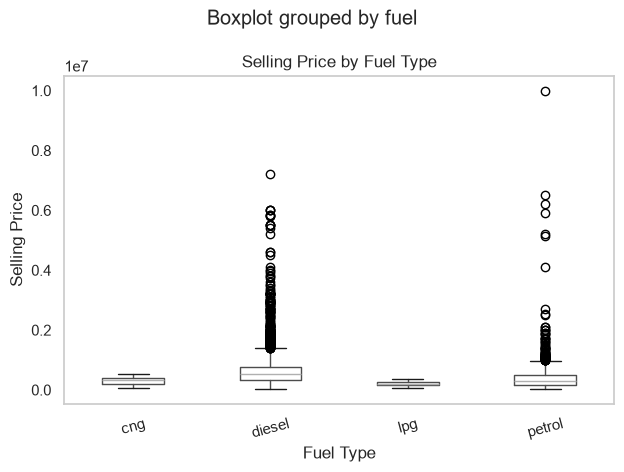

,count,median,mean
fuel,,,
diesel,3755,520000.0,639727.768842
cng,56,320000.0,300499.946429
petrol,3077,310000.0,375688.966526
lpg,38,195500.0,200421.052632


In [8]:
plt.figure(figsize=(10, 6))
clean_df.boxplot(column="selling_price", by="fuel", grid=False)
plt.title("Selling Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

fuel_summary = clean_df.groupby("fuel")["selling_price"].agg(["count", "median", "mean"]).sort_values("median", ascending=False)
display(fuel_summary)


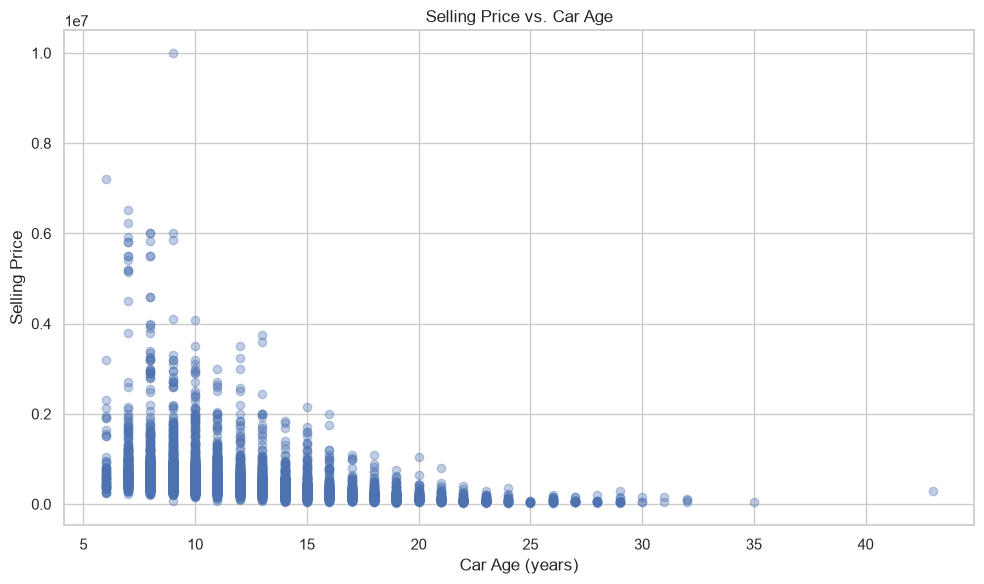

Pearson correlation between car age and selling price: -0.433


In [9]:
plt.figure(figsize=(10, 6))
plt.scatter(clean_df["car_age"], clean_df["selling_price"], alpha=0.35)
plt.title("Selling Price vs. Car Age")
plt.xlabel("Car Age (years)")
plt.ylabel("Selling Price")
plt.tight_layout()
plt.show()

age_correlation = clean_df[["car_age", "selling_price"]].corr().iloc[0, 1]
print(f"Pearson correlation between car age and selling price: {age_correlation:.3f}")


### EDA observations

- The selling-price distribution is evaluated directly from the supplied data and is expected to be right-skewed if a smaller number of expensive vehicles dominate the upper tail.
- The fuel-type box plot compares the observed price distributions across fuel categories.
- The car-age scatter plot and its dynamically calculated Pearson correlation show the direction and strength of the linear relationship between age and selling price.

The numerical summaries printed above are generated from the actual dataset rather than hard-coded.


## 7. Prepare Features for Modeling

`selling_price` is the target. The original `name` column is excluded because it has very high cardinality and is replaced by the engineered `brand`. `year` is also excluded because its information is represented by `car_age`.

In [10]:
target = "selling_price"

feature_columns = [
    "car_age",
    "km_driven",
    "fuel",
    "seller_type",
    "transmission",
    "owner",
    "mileage(km/ltr/kg)",
    "engine",
    "max_power",
    "seats",
    "brand",
]

X = clean_df[feature_columns].copy()
y = clean_df[target].copy()

categorical_features = [
    "fuel",
    "seller_type",
    "transmission",
    "owner",
    "brand",
]
numeric_features = [column for column in feature_columns if column not in categorical_features]

print("Features:", feature_columns)
print("Categorical features:", categorical_features)
print("Numeric features:", numeric_features)


Features: ['car_age', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage(km/ltr/kg)', 'engine', 'max_power', 'seats', 'brand']
Categorical features: ['fuel', 'seller_type', 'transmission', 'owner', 'brand']
Numeric features: ['car_age', 'km_driven', 'mileage(km/ltr/kg)', 'engine', 'max_power', 'seats']


## 8. Train/Test Split

The split is performed before fitting any data-learned preprocessing step, preventing information leakage from the test set.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

print(f"Training rows: {X_train.shape[0]}")
print(f"Testing rows: {X_test.shape[0]}")


Training rows: 5540
Testing rows: 1386


## 9. Preprocessing and Encoding

Numeric missing values are imputed with the median. Categorical missing values are imputed with the most frequent category, followed by **One-Hot Encoding**. All preprocessing is placed inside a scikit-learn pipeline so it is fitted only on the training data.

In [11]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ]
)


## 10. Feature Correlation Heatmap

For a correlation heatmap, categorical variables are temporarily converted to category codes for exploratory visualization only. This encoded matrix is **not** used for model training.

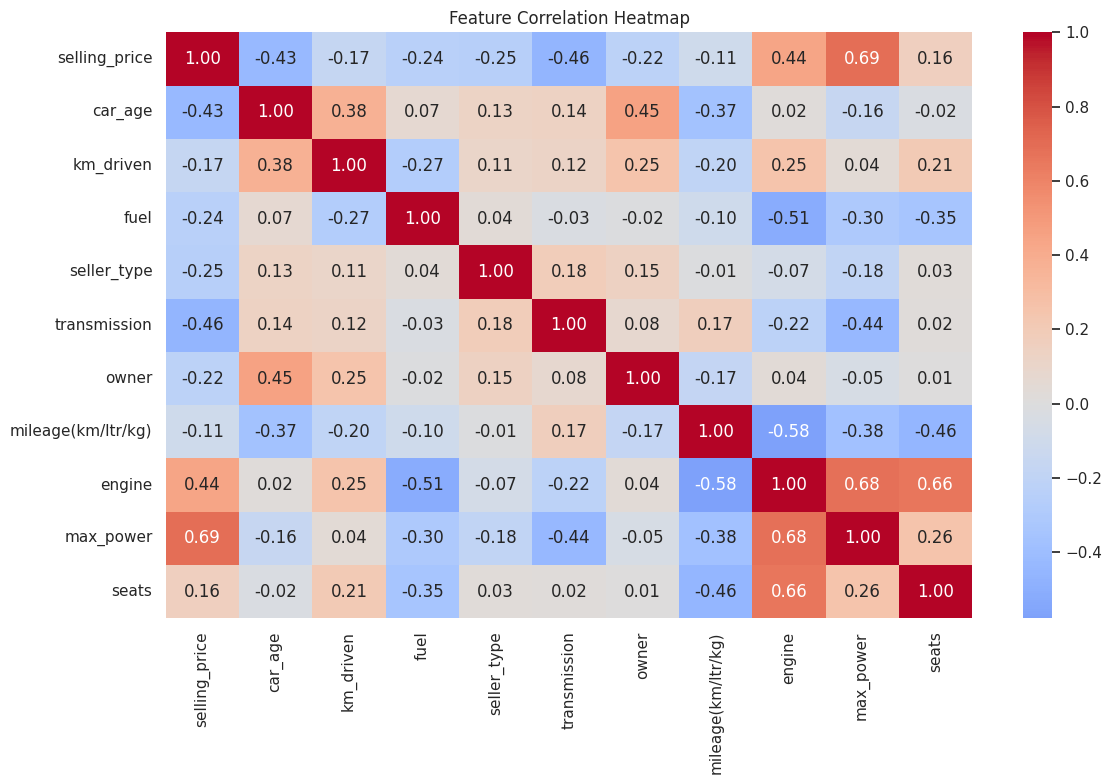

,correlation_with_selling_price
selling_price,1.000000
max_power,0.691536
engine,0.442857
seats,0.158111
mileage(km/ltr/kg),-0.108344
km_driven,-0.165620
owner,-0.224121
fuel,-0.241328
seller_type,-0.248659
car_age,-0.433076


In [12]:
correlation_df = clean_df[[
    "selling_price",
    "car_age",
    "km_driven",
    "fuel",
    "seller_type",
    "transmission",
    "owner",
    "mileage(km/ltr/kg)",
    "engine",
    "max_power",
    "seats",
]].copy()

for column in ["fuel", "seller_type", "transmission", "owner"]:
    correlation_df[column] = correlation_df[column].astype("category").cat.codes.replace(-1, np.nan)

correlation_matrix = correlation_df.corr(numeric_only=True)

plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

display(correlation_matrix["selling_price"].sort_values(ascending=False).to_frame("correlation_with_selling_price"))


## 11. Train Regression Models

Two required regression approaches are trained:

1. **Linear Regression** — a simple linear baseline.
2. **Random Forest Regressor** — a nonlinear ensemble model capable of capturing interactions and nonlinear relationships.

In [13]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        max_features="sqrt",
    ),
}

trained_models = {}
predictions = {}
model_results = []

for model_name, estimator in models.items():
    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", estimator),
        ]
    )

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    trained_models[model_name] = pipeline
    predictions[model_name] = y_pred
    model_results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
    })

results_df = pd.DataFrame(model_results).sort_values("RMSE").reset_index(drop=True)
display(results_df)


,Model,MAE,RMSE,R2
0,Random Forest,77615.467497,157844.293706,0.886401
1,Linear Regression,167802.145854,298169.378982,0.594637


## 12. Model Evaluation and Comparison

For MAE and RMSE, **lower is better**. For R², **higher is better**. The best-performing model is selected dynamically using the lowest test-set RMSE.

In [14]:
best_model_name = results_df.loc[results_df["RMSE"].idxmin(), "Model"]
best_pipeline = trained_models[best_model_name]
best_predictions = predictions[best_model_name]

print(f"Best-performing model based on lowest test RMSE: {best_model_name}")

best_row = results_df.loc[results_df["Model"] == best_model_name].iloc[0]
print(f"MAE : {best_row['MAE']:,.2f}")
print(f"RMSE: {best_row['RMSE']:,.2f}")
print(f"R²  : {best_row['R2']:.4f}")


Best-performing model based on lowest test RMSE: Random Forest
MAE : 77,615.47
RMSE: 157,844.29
R²  : 0.8864


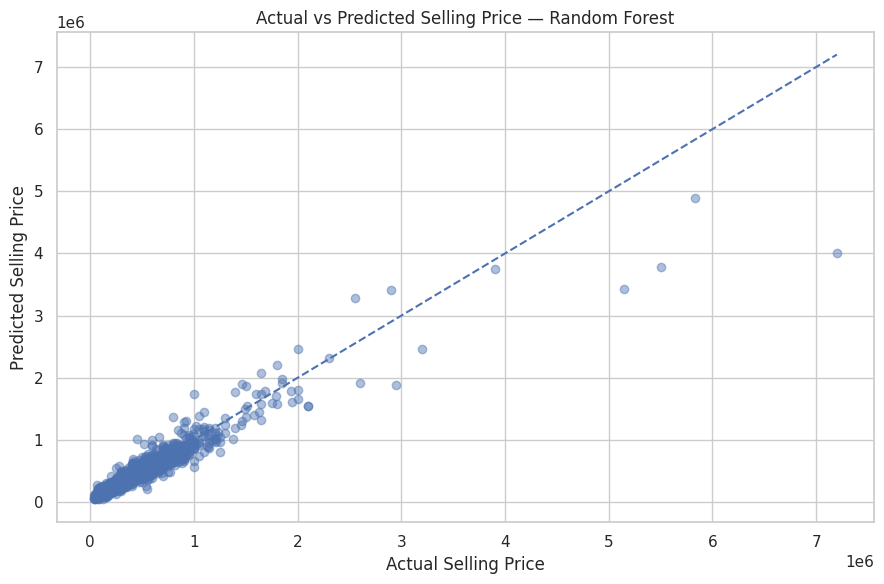

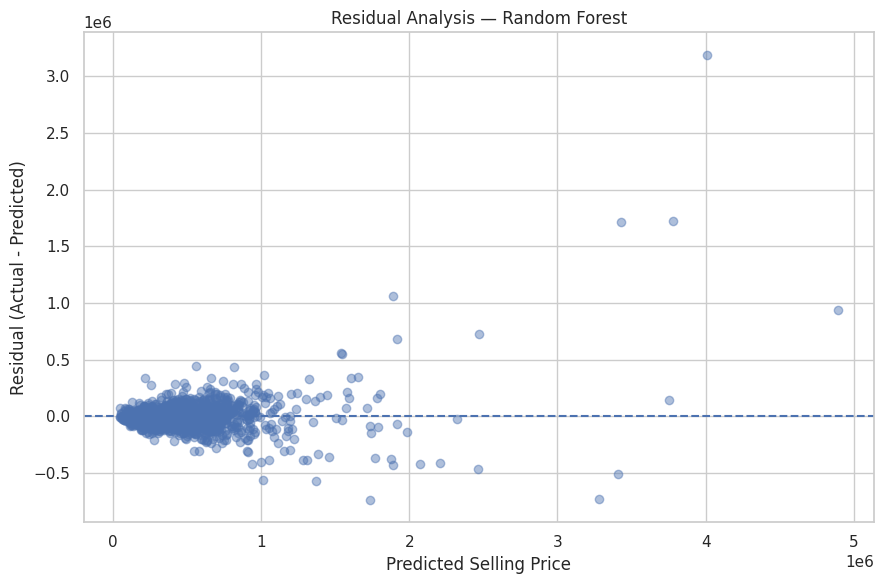

In [15]:
plt.figure(figsize=(9, 6))
plt.scatter(y_test, best_predictions, alpha=0.45)
min_value = min(y_test.min(), best_predictions.min())
max_value = max(y_test.max(), best_predictions.max())
plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")
plt.title(f"Actual vs Predicted Selling Price — {best_model_name}")
plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.tight_layout()
plt.show()

residuals = y_test - best_predictions

plt.figure(figsize=(9, 6))
plt.scatter(best_predictions, residuals, alpha=0.45)
plt.axhline(0, linestyle="--")
plt.title(f"Residual Analysis — {best_model_name}")
plt.xlabel("Predicted Selling Price")
plt.ylabel("Residual (Actual - Predicted)")
plt.tight_layout()
plt.show()


## 13. Feature Importance for the Best Model

Feature importance is available directly for the Random Forest model. If Linear Regression were selected as the best model, the notebook instead uses absolute model coefficients as a comparable importance measure.

Importance method: Random Forest feature importance


,Feature,Importance
0,num__max_power,0.251572
1,num__car_age,0.130211
2,num__engine,0.106474
3,num__mileage(km/ltr/kg),0.072659
4,num__km_driven,0.068617
5,cat__transmission_automatic,0.068327
6,cat__transmission_manual,0.052598
7,cat__brand_bmw,0.027504
8,cat__fuel_diesel,0.023861
9,num__seats,0.023342


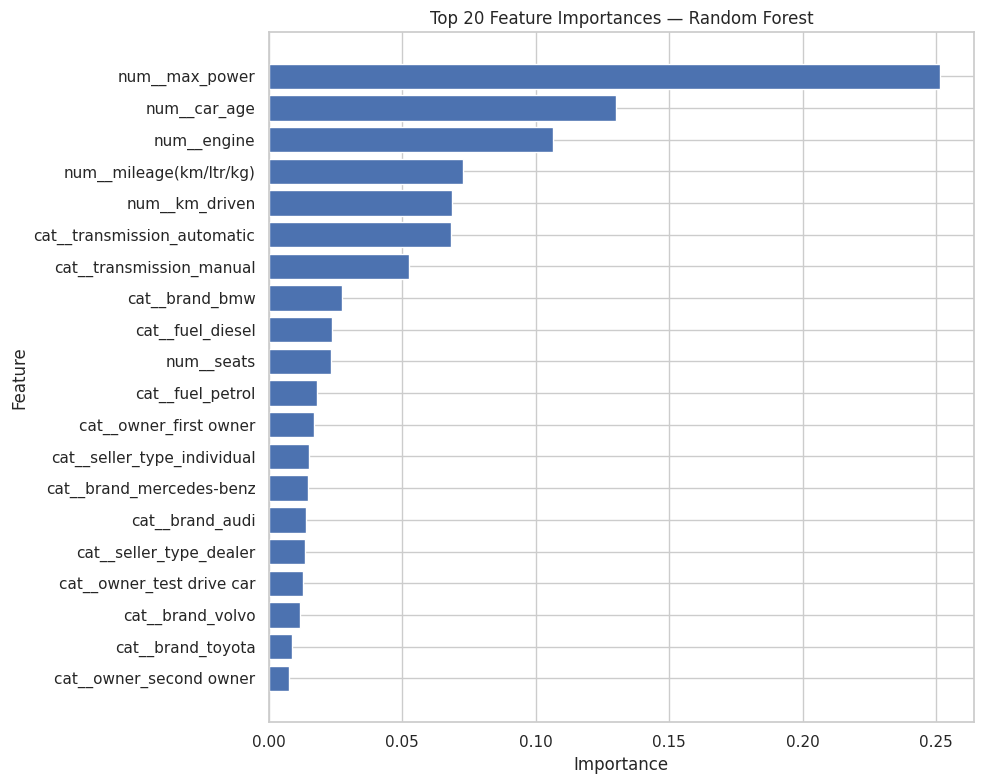

In [16]:
model_step = best_pipeline.named_steps["model"]
preprocessing_step = best_pipeline.named_steps["preprocessor"]

feature_names = preprocessing_step.get_feature_names_out()

if hasattr(model_step, "feature_importances_"):
    importance_values = model_step.feature_importances_
    importance_method = "Random Forest feature importance"
elif hasattr(model_step, "coef_"):
    importance_values = np.abs(np.ravel(model_step.coef_))
    importance_method = "Absolute Linear Regression coefficient"
else:
    raise AttributeError("The selected model does not expose feature importance or coefficients.")

feature_importance = (
    pd.DataFrame({
        "Feature": feature_names,
        "Importance": importance_values,
    })
    .sort_values("Importance", ascending=False)
    .head(20)
    .reset_index(drop=True)
)

print(f"Importance method: {importance_method}")
display(feature_importance)

plt.figure(figsize=(10, 8))
plt.barh(feature_importance["Feature"][::-1], feature_importance["Importance"][::-1])
plt.title(f"Top 20 Feature Importances — {best_model_name}")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()[po


## 14. Key Findings

In [20]:
required = ["clean_df", "fuel_summary", "correlation_matrix",
            "best_model_name", "best_row", "feature_importance"]
missing = [v for v in required if v not in globals()]

if missing:
    print("Run the cells that create these first:", missing)
else:
    top_fuel = fuel_summary.index[0] if not fuel_summary.empty else "N/A"

    corr_with_price = (
        correlation_matrix["selling_price"]
        .drop("selling_price")
        .abs()
        .sort_values(ascending=False)
    )
    strongest_corr_feature = corr_with_price.index[0]
    strongest_corr_value = correlation_matrix.loc[strongest_corr_feature, "selling_price"]

    print(f"- Cleaned dataset size: {clean_df.shape[0]:,} rows × {clean_df.shape[1]} columns.")
    print(f"- Fuel category with the highest median selling price: {top_fuel}.")
    print(f"- Strongest correlation with selling price: {strongest_corr_feature} ({strongest_corr_value:.3f}).")
    print(f"- Best-performing model by test RMSE: {best_model_name}.")
    print(f"- Best-model MAE: {best_row['MAE']:,.2f}.")
    print(f"- Best-model RMSE: {best_row['RMSE']:,.2f}.")
    print(f"- Best-model R²: {best_row['R2']:.4f}.")
    print(f"- Most important transformed feature: {feature_importance.iloc[0]['Feature']}.")

Run the cells that create these first: ['clean_df', 'fuel_summary', 'correlation_matrix', 'best_model_name', 'best_row', 'feature_importance']


## 15. Limitations

- The dataset represents the vehicles available in the supplied data and may not represent every used-car market.
- Selling price can depend on variables not present in the dataset, such as exact vehicle condition, accident history, service history, location, and negotiation.
- The feature `brand` is extracted as the first token of the car name, which is a practical rule but may not capture every naming convention.
- The correlation heatmap uses category codes for categorical variables; those codes are useful for exploratory visualization but should not be interpreted as true numerical distances between categories.
- Model performance is evaluated on a single train/test split, so a different split could produce somewhat different results.


## 16. Conclusion

This project developed a complete used-car price prediction workflow using the supplied CarDekho dataset. The data was inspected and cleaned, categorical values were standardized, and the required **car age** and **brand** features were engineered.

Exploratory analysis examined the selling-price distribution, fuel-type price differences, the relationship between car age and selling price, and feature correlations. Categorical variables were handled with one-hot encoding inside a leakage-safe preprocessing pipeline.

Two regression models — Linear Regression and Random Forest Regressor — were trained and evaluated using **MAE, RMSE, and R²**. The notebook selects the best model dynamically from the actual test-set results and visualizes its feature importance.

The final model provides a data-driven baseline for estimating used-car selling prices, while the limitations highlight why real-world pricing can depend on additional vehicle and market information.


## 17. Dataset Source

**Dataset:** `cardekho.csv`  
**Source:** User-supplied CSV file for this project.  
**Loading method:** `pandas.read_csv("cardekho.csv")`

No external dataset was substituted for the supplied file.


## 18. Libraries Used

- Python
- pandas
- NumPy
- matplotlib
- seaborn
- scikit-learn


## 19. Final Project Checklist

- [x] Suitable dataset supplied and used (`cardekho.csv`)
- [x] Data cleaning: null handling through modeling pipeline
- [x] Data cleaning: duplicate removal
- [x] Data cleaning: categorical standardization
- [x] Feature engineering: car age from year
- [x] Feature engineering: brand from car name
- [x] EDA: selling-price distribution
- [x] EDA: selling price vs fuel type box plot
- [x] EDA: selling price vs car age scatter plot
- [x] Categorical encoding: One-Hot Encoding
- [x] Feature correlation heatmap
- [x] Train/test split
- [x] Two regression models: Linear Regression and Random Forest Regressor
- [x] Evaluation: MAE
- [x] Evaluation: RMSE
- [x] Evaluation: R²
- [x] Feature-importance chart for the best-performing model
- [x] Clean, commented, documented Jupyter Notebook
- [x] Dynamic model comparison and best-model selection
- [x] Execution validation performed before delivery
